In [8]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

# visual
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing / pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# model selection / Validation
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_predict
)

# eval
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)
from scipy.stats import ks_2samp

# feature explainability
import shap

In [9]:
df = pd.read_csv('/content/sample_data/credit_risk_dataset.csv').drop_duplicates().reset_index(drop=True)

In [10]:
# Check missing values count and percentage
missing_data = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})
print(missing_data[missing_data['Missing Count'] > 0])

                   Missing Count  Missing Percentage
person_emp_length            887            2.736303
loan_int_rate               3095            9.547754


## Phase 1: EDA

loan_status
0    25327
1     7089
Name: count, dtype: int64

Default Percentage: 21.87 %


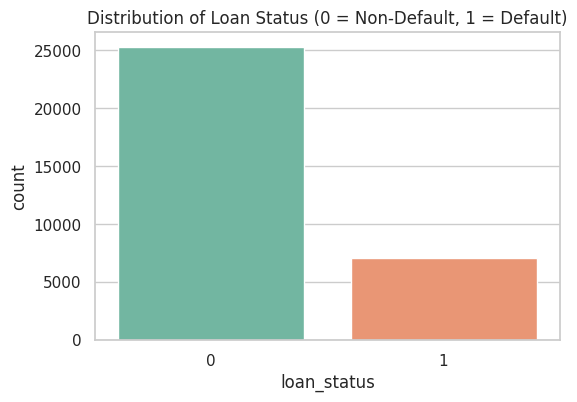

In [11]:
# Set style
sns.set_theme(style="whitegrid")

# Count and percentage of loan status
print(df['loan_status'].value_counts())
print("\nDefault Percentage:", (df['loan_status'].mean() * 100).round(2), "%")

# Quick plot
plt.figure(figsize=(6, 4))
sns.countplot(x='loan_status', data=df, palette='Set2', hue='loan_status', legend=False)
plt.title('Distribution of Loan Status (0 = Non-Default, 1 = Default)')
plt.show()

In [12]:
# Format pandas to display floats with 2 decimal places and suppress scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [13]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.00,32416.00,31529.00,32416.00,29321.00,32416.00,32416.00,32416.00
mean,27.75,66091.64,4.79,9593.85,11.02,0.22,0.17,5.81
std,6.35,62015.58,4.15,6322.73,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38542.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79218.00,7.00,12250.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [14]:
# Identify logical anomalies (e.g., age > 100 or employment length > age)
anomalies = df[(df['person_age'] > 100) | (df['person_emp_length'] >= df['person_age'])]
print(f"Number of outlier rows to clean: {len(anomalies)}")

Number of outlier rows to clean: 7


In [15]:
# Calculate default rate percentage grouped by loan grade
default_by_grade = df.groupby('loan_grade')['loan_status'].mean() * 100
display(default_by_grade.round(2))

,loan_status
loan_grade,
A,9.96
B,16.32
C,20.75
D,59.06
E,64.49
F,70.54
G,98.44


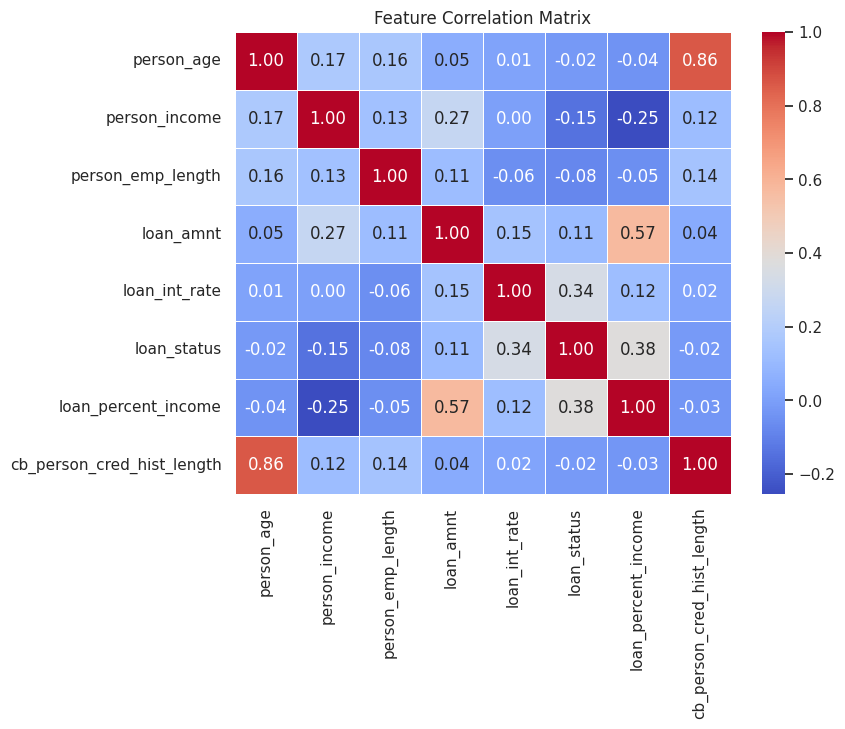

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

In [17]:
# Default rate by Loan Intent
print("--- Default Rate by Loan Intent ---")
print(df.groupby('loan_intent')['loan_status'].mean() * 100)

# Default rate by Home Ownership
print("\n--- Default Rate by Home Ownership ---")
print(df.groupby('person_home_ownership')['loan_status'].mean() * 100)

# Default rate by Historical Default on File
print("\n--- Default Rate by Historical Default ---")
print(df.groupby('cb_person_default_on_file')['loan_status'].mean() * 100)

--- Default Rate by Loan Intent ---
loan_intent
DEBTCONSOLIDATION   28.68
EDUCATION           17.25
HOMEIMPROVEMENT     26.15
MEDICAL             26.76
PERSONAL            19.90
VENTURE             14.85
Name: loan_status, dtype: float64

--- Default Rate by Home Ownership ---
person_home_ownership
MORTGAGE   12.62
OTHER      31.13
OWN         7.49
RENT       31.61
Name: loan_status, dtype: float64

--- Default Rate by Historical Default ---
cb_person_default_on_file
N   18.43
Y   37.87
Name: loan_status, dtype: float64


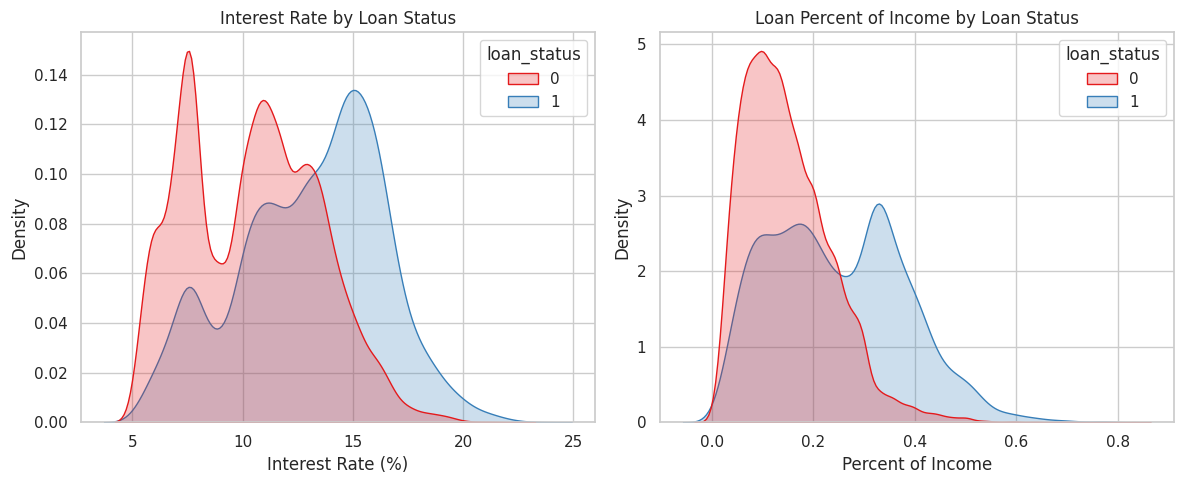

In [18]:
plt.figure(figsize=(12, 5))

# Plot 1: Interest Rate vs Loan Status
plt.subplot(1, 2, 1)
sns.kdeplot(data=df, x='loan_int_rate', hue='loan_status', fill=True, common_norm=False, palette='Set1')
plt.title('Interest Rate by Loan Status')
plt.xlabel('Interest Rate (%)')

# Plot 2: Loan Percent Income vs Loan Status
plt.subplot(1, 2, 2)
sns.kdeplot(data=df, x='loan_percent_income', hue='loan_status', fill=True, common_norm=False, palette='Set1')
plt.title('Loan Percent of Income by Loan Status')
plt.xlabel('Percent of Income')

plt.tight_layout()
plt.show()

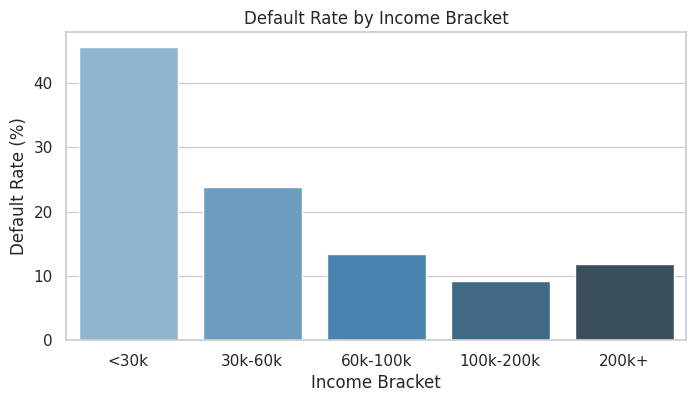

In [19]:
# Create income brackets (bins)
bins = [0, 30000, 60000, 100000, 200000, df['person_income'].max()]
labels = ['<30k', '30k-60k', '60k-100k', '100k-200k', '200k+']
df['income_bracket'] = pd.cut(df['person_income'], bins=bins, labels=labels)

# Calculate default rate per bracket
bracket_defaults = df.groupby('income_bracket', observed=False)['loan_status'].mean() * 100

# Plot
plt.figure(figsize=(8, 4))
sns.barplot(x=bracket_defaults.index, y=bracket_defaults.values, palette='Blues_d', hue=bracket_defaults.index, legend=False)
plt.title('Default Rate by Income Bracket')
plt.ylabel('Default Rate (%)')
plt.xlabel('Income Bracket')
plt.show()

# Drop the temporary column so it doesn't mess up later steps
df = df.drop(columns=['income_bracket'])

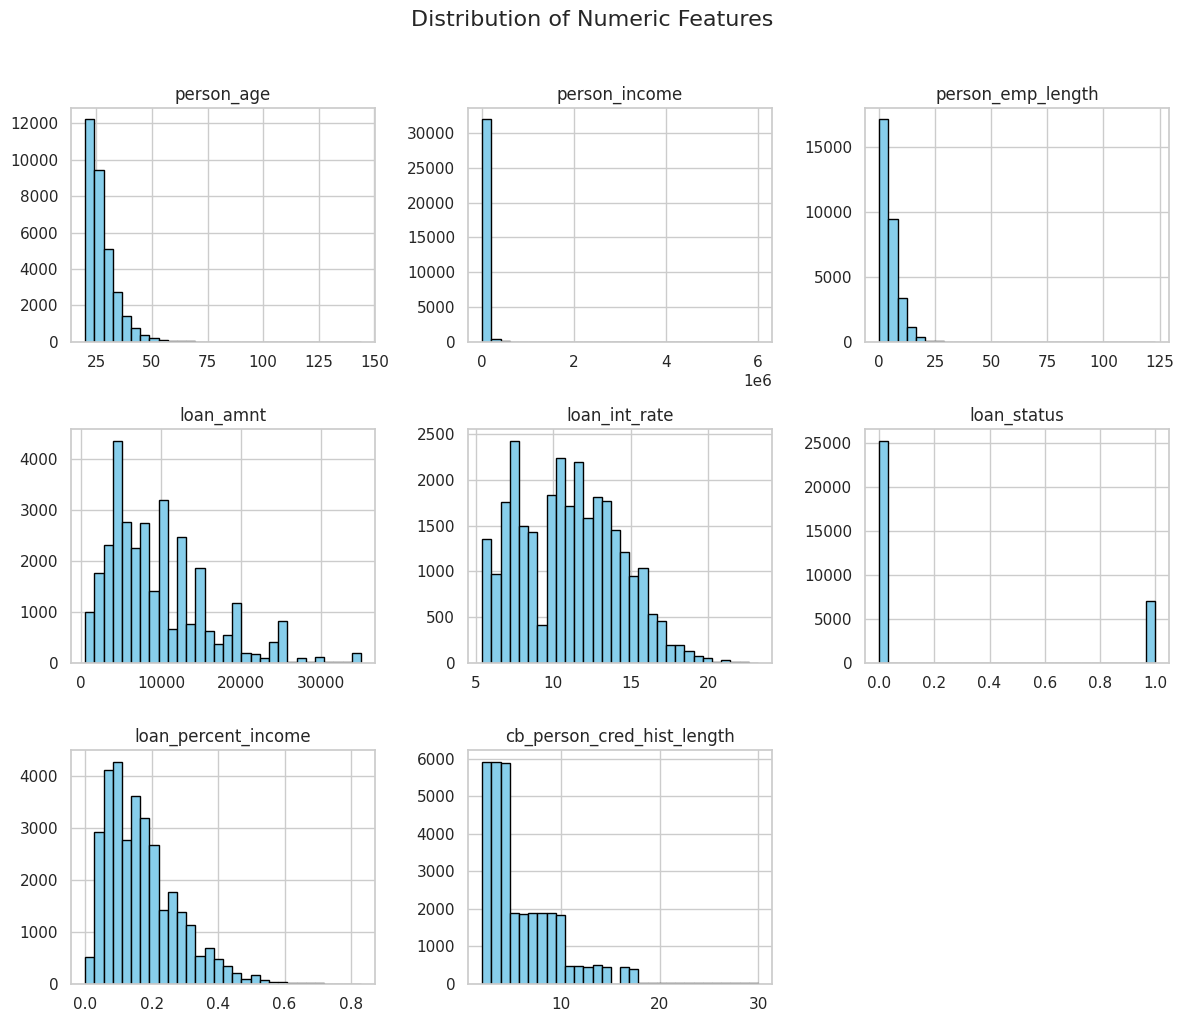

In [20]:
# Plot histograms for all numeric columns at once
df.select_dtypes(include=['number']).hist(bins=30, figsize=(12, 10), color='skyblue', edgecolor='black')
plt.suptitle('Distribution of Numeric Features', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

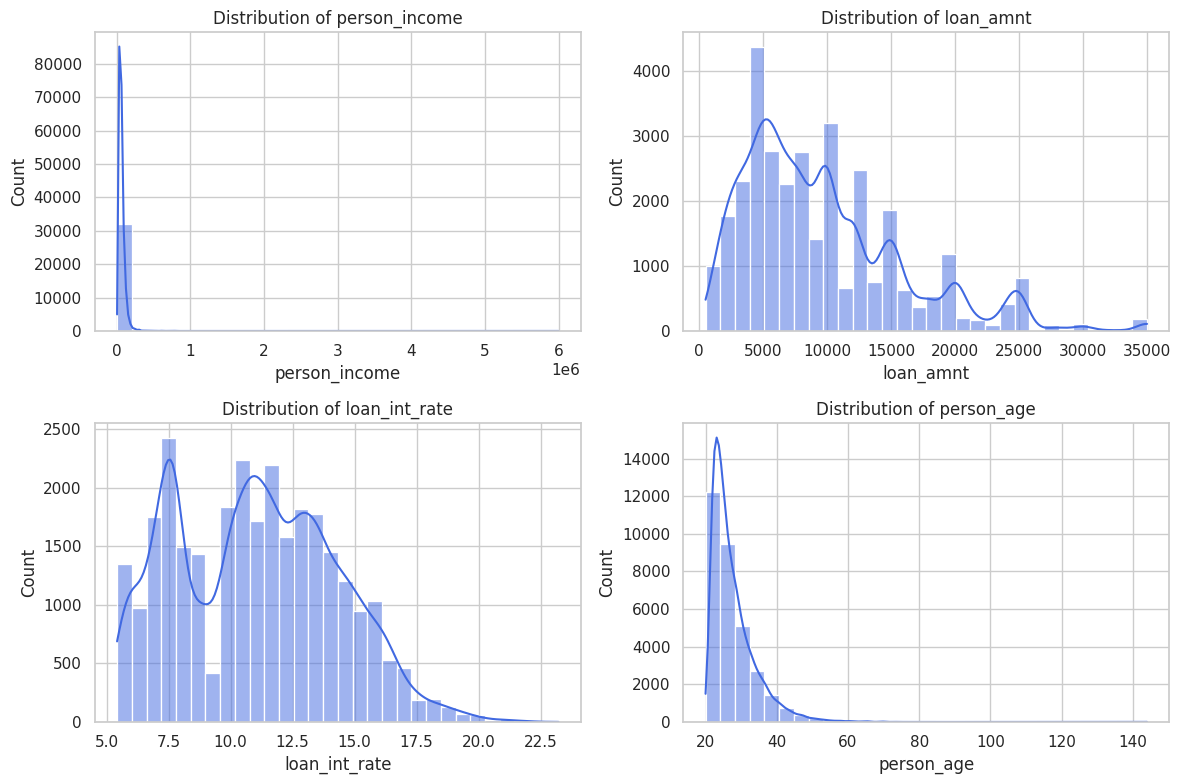

In [21]:
key_cols = ['person_income', 'loan_amnt', 'loan_int_rate', 'person_age']

plt.figure(figsize=(12, 8))
for i, col in enumerate(key_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True, bins=30, color='royalblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

## Phase 2: Data Cleaning, Preprocessing & Train-Test Split

In [22]:
# Cleaning from anomalies
valid_age = df['person_age'] <= 100
valid_emp_length = df['person_emp_length'] <= (df['person_age'] - 18)

df_cleaned = df[valid_age & valid_emp_length].copy()

print(f"Original dataset rows: {len(df)}")
print(f"Rows after cleaning anomalies: {len(df_cleaned)}")

# Separating Target form features
X = df_cleaned.drop(columns=['loan_status'])
y = df_cleaned['loan_status']

# Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Keeps the 22% default ratio balanced in both sets!
)

# Shape checks
print(f"\nX_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Original dataset rows: 32416
Rows after cleaning anomalies: 23742

X_train shape: (18993, 11)
X_test shape: (4749, 11)


In [23]:
# Defining processor after test split,

# feature definitions
numeric_cols = [
    'person_age', 'person_income', 'person_emp_length',
    'loan_amnt', 'loan_int_rate', 'loan_percent_income',
    'cb_person_cred_hist_length'
]
ordinal_cols = ['loan_grade']
nominal_cols = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']

# preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

grade_order = [['A', 'B', 'C', 'D', 'E', 'F', 'G']]
ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=grade_order, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# combine into main preprocessor
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_cols),
    ('ord', ordinal_transformer, ordinal_cols),
    ('nom', nominal_transformer, nominal_cols)
])

## Evaluation Code

In [24]:
def evaluate(model_name, probs, y, threshold=0.5, is_test_set=False):
    """
    Computes credit risk metrics, prints reports,
    and generates a unified 2x2 Risk Dashboard.
    """
    prauc = average_precision_score(y, probs)
    roc_auc = roc_auc_score(y, probs)
    gini = 2 * roc_auc - 1

    defaults = probs[y == 1]
    non_defaults = probs[y == 0]
    ks_stat, _ = ks_2samp(defaults, non_defaults)

    prefix = "FINAL TEST SET AUDIT" if is_test_set else "Cross-Validation Audit"
    print(f"=== {prefix} ({model_name}) ===")
    print(f"PR-AUC           : {prauc:.4f}")
    print(f"ROC-AUC          : {roc_auc:.4f}")
    print(f"Gini Coefficient : {gini:.4f}")
    print(f"KS Statistic     : {ks_stat:.4f}\n")

    preds = (probs >= threshold).astype(int)
    print(f"Classification Report (Threshold = {threshold:.4f}):")
    print(classification_report(y, preds, target_names=['Non-Default', 'Default']))

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))

    # roc curve
    fpr, tpr, _ = roc_curve(y, probs)
    axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
    axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
    axes[0, 0].set_xlabel('False Positive Rate')
    axes[0, 0].set_ylabel('True Positive Rate')
    axes[0, 0].set_title(f'ROC Curve (Gini: {gini:.3f})')
    axes[0, 0].legend(loc="lower right")
    axes[0, 0].grid(True, alpha=0.3)

    # precision-recall curve
    precision, recall, _ = precision_recall_curve(y, probs)
    axes[0, 1].plot(recall, precision, color='purple', lw=2, label=f'PR Curve (AUC = {prauc:.3f})')
    axes[0, 1].set_xlabel('Recall')
    axes[0, 1].set_ylabel('Precision')
    axes[0, 1].set_title('Precision-Recall Curve')
    axes[0, 1].legend(loc="lower left")
    axes[0, 1].grid(True, alpha=0.3)

    # ks statistic plot
    df_ks = pd.DataFrame({'prob': probs, 'target': y}).sort_values(by='prob')
    df_ks['cum_non_default'] = (df_ks['target'] == 0).cumsum() / (df_ks['target'] == 0).sum()
    df_ks['cum_default'] = (df_ks['target'] == 1).cumsum() / (df_ks['target'] == 1).sum()
    df_ks['ks_diff'] = np.abs(df_ks['cum_non_default'] - df_ks['cum_default'])

    max_ks_idx = df_ks['ks_diff'].idxmax()
    max_ks_row = df_ks.loc[max_ks_idx]

    axes[1, 0].plot(df_ks['prob'], df_ks['cum_non_default'], label='Non-Defaults (Goods)', color='green', lw=2)
    axes[1, 0].plot(df_ks['prob'], df_ks['cum_default'], label='Defaults (Bads)', color='red', lw=2)
    axes[1, 0].vlines(x=max_ks_row['prob'],
                     ymin=min(max_ks_row['cum_non_default'], max_ks_row['cum_default']),
                     ymax=max(max_ks_row['cum_non_default'], max_ks_row['cum_default']),
                     color='blue', linestyle='--', lw=2, label=f'KS = {ks_stat:.3f}')
    axes[1, 0].set_xlabel('Predicted Default Probability')
    axes[1, 0].set_ylabel('Cumulative Distribution')
    axes[1, 0].set_title('KS Separation Plot')
    axes[1, 0].legend(loc="lower right")
    axes[1, 0].grid(True, alpha=0.3)

    # confusion matrix
    cm = confusion_matrix(y, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Default', 'Default'])
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[1, 1])
    axes[1, 1].set_title(f'Confusion Matrix (Threshold {threshold:.2f})')
    axes[1, 1].grid(False)

    plt.tight_layout()
    plt.show()

    return {'prauc': prauc, 'roc_auc': roc_auc, 'gini': gini, 'ks': ks_stat}

## Phase 3: Training

### Model 1, Baseline: Logistical Regression

In [25]:
# logistic regression pipeline & grid search
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

param_grid_lr = {
    'classifier__C': [0.01, 0.1, 1.0, 10.0],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__class_weight': ['balanced', None]
}

grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=5,
    scoring='average_precision',
    n_jobs=-1
)

print("Fitting Logistic Regression...")
grid_search_lr.fit(X_train, y_train)

print(f"LR best pr-AUC: {grid_search_lr.best_score_:.4f}")
print(f"Best Params: {grid_search_lr.best_params_}")

Fitting Logistic Regression...
LR best pr-AUC: 0.7200
Best Params: {'classifier__C': 1.0, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}


=== Cross-Validation Audit (Logistic Regression) ===
PR-AUC           : 0.7186
ROC-AUC          : 0.8682
Gini Coefficient : 0.7364
KS Statistic     : 0.5837

Classification Report (Threshold = 0.5000):
              precision    recall  f1-score   support

 Non-Default       0.87      0.95      0.91     14698
     Default       0.75      0.53      0.62      4295

    accuracy                           0.85     18993
   macro avg       0.81      0.74      0.77     18993
weighted avg       0.85      0.85      0.84     18993



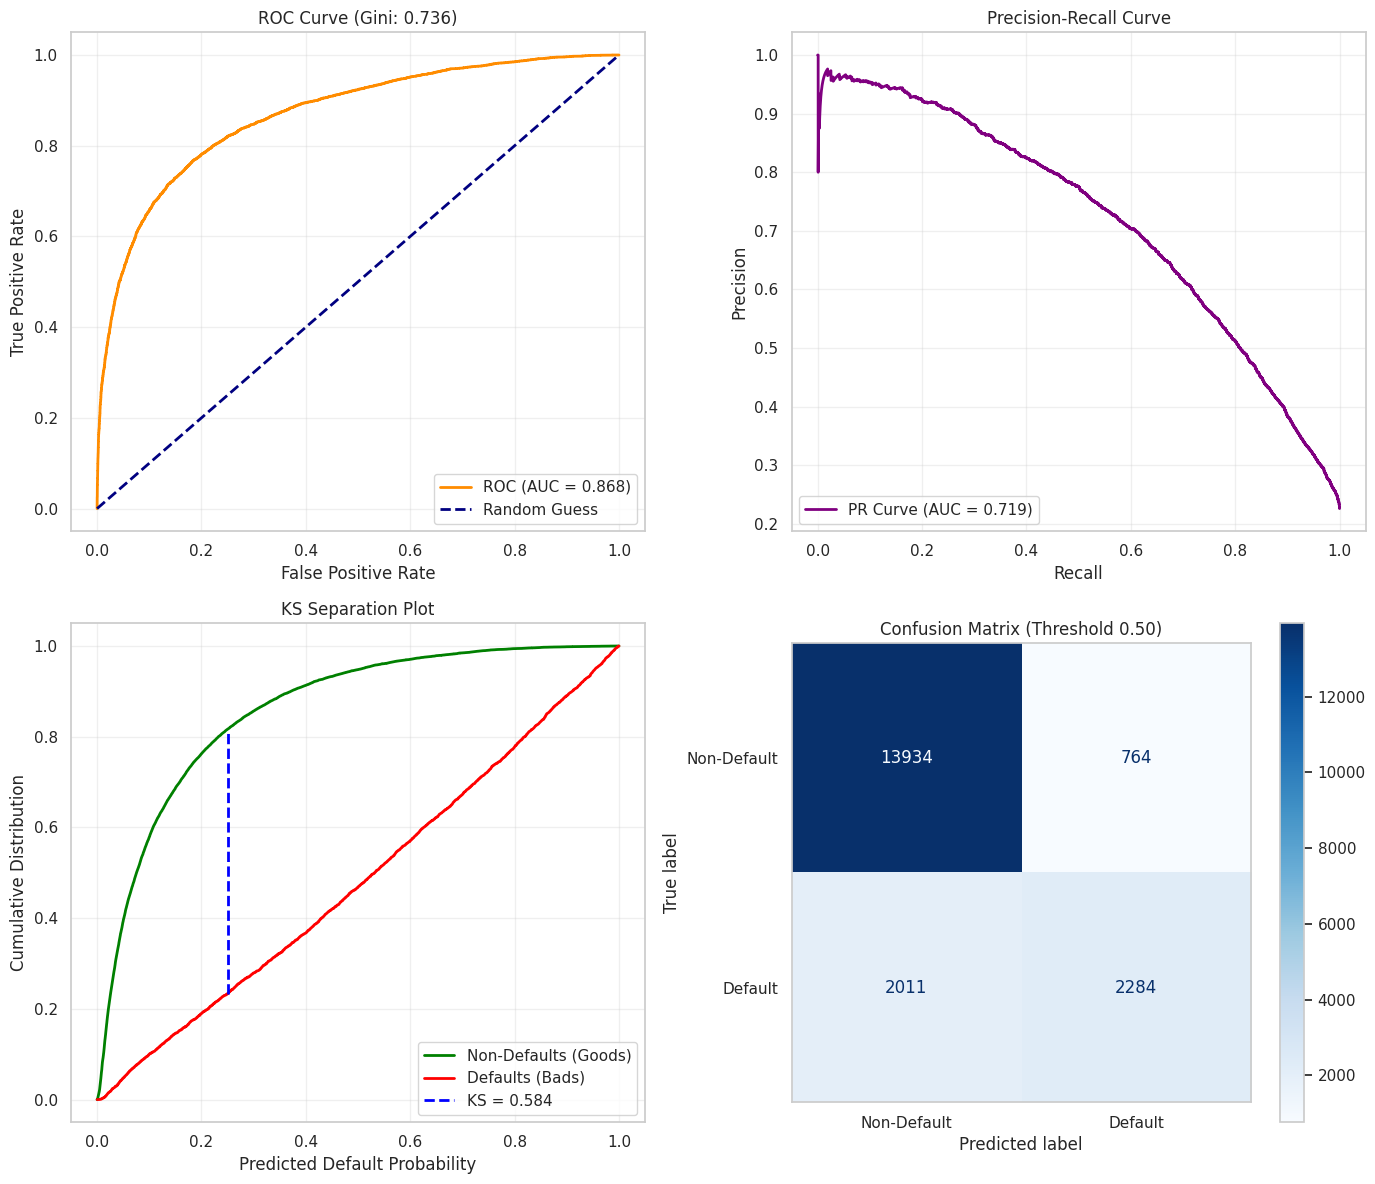

In [26]:
best_lr = grid_search_lr.best_estimator_
oof_probs_lr = cross_val_predict(best_lr, X_train, y_train, cv=5, method='predict_proba', n_jobs=-1)[:, 1]

metrics_lr = evaluate("Logistic Regression", oof_probs_lr, y_train)
cv_prauc_lr, cv_roc_auc_lr, cv_gini_lr, cv_ks_lr = (
    metrics_lr['prauc'], metrics_lr['roc_auc'], metrics_lr['gini'], metrics_lr['ks']
)

### Model 2: Random forest

In [27]:
# random forest pipeline & grid search
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': ['balanced', None]
}

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=5,
    scoring='average_precision',
    n_jobs=-1
)

print("Fitting Random Forest")
grid_search_rf.fit(X_train, y_train)

print(f"\nRF Best PR-AUC: {grid_search_rf.best_score_:.4f}")
print(f"Best Params: {grid_search_rf.best_params_}")

Fitting Random Forest

RF Best PR-AUC: 0.8970
Best Params: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}


=== Cross-Validation Audit (Random Forest) ===
PR-AUC           : 0.8969
ROC-AUC          : 0.9361
Gini Coefficient : 0.8722
KS Statistic     : 0.7474

Classification Report (Threshold = 0.5000):
              precision    recall  f1-score   support

 Non-Default       0.93      1.00      0.96     14698
     Default       0.98      0.73      0.84      4295

    accuracy                           0.94     18993
   macro avg       0.95      0.86      0.90     18993
weighted avg       0.94      0.94      0.93     18993



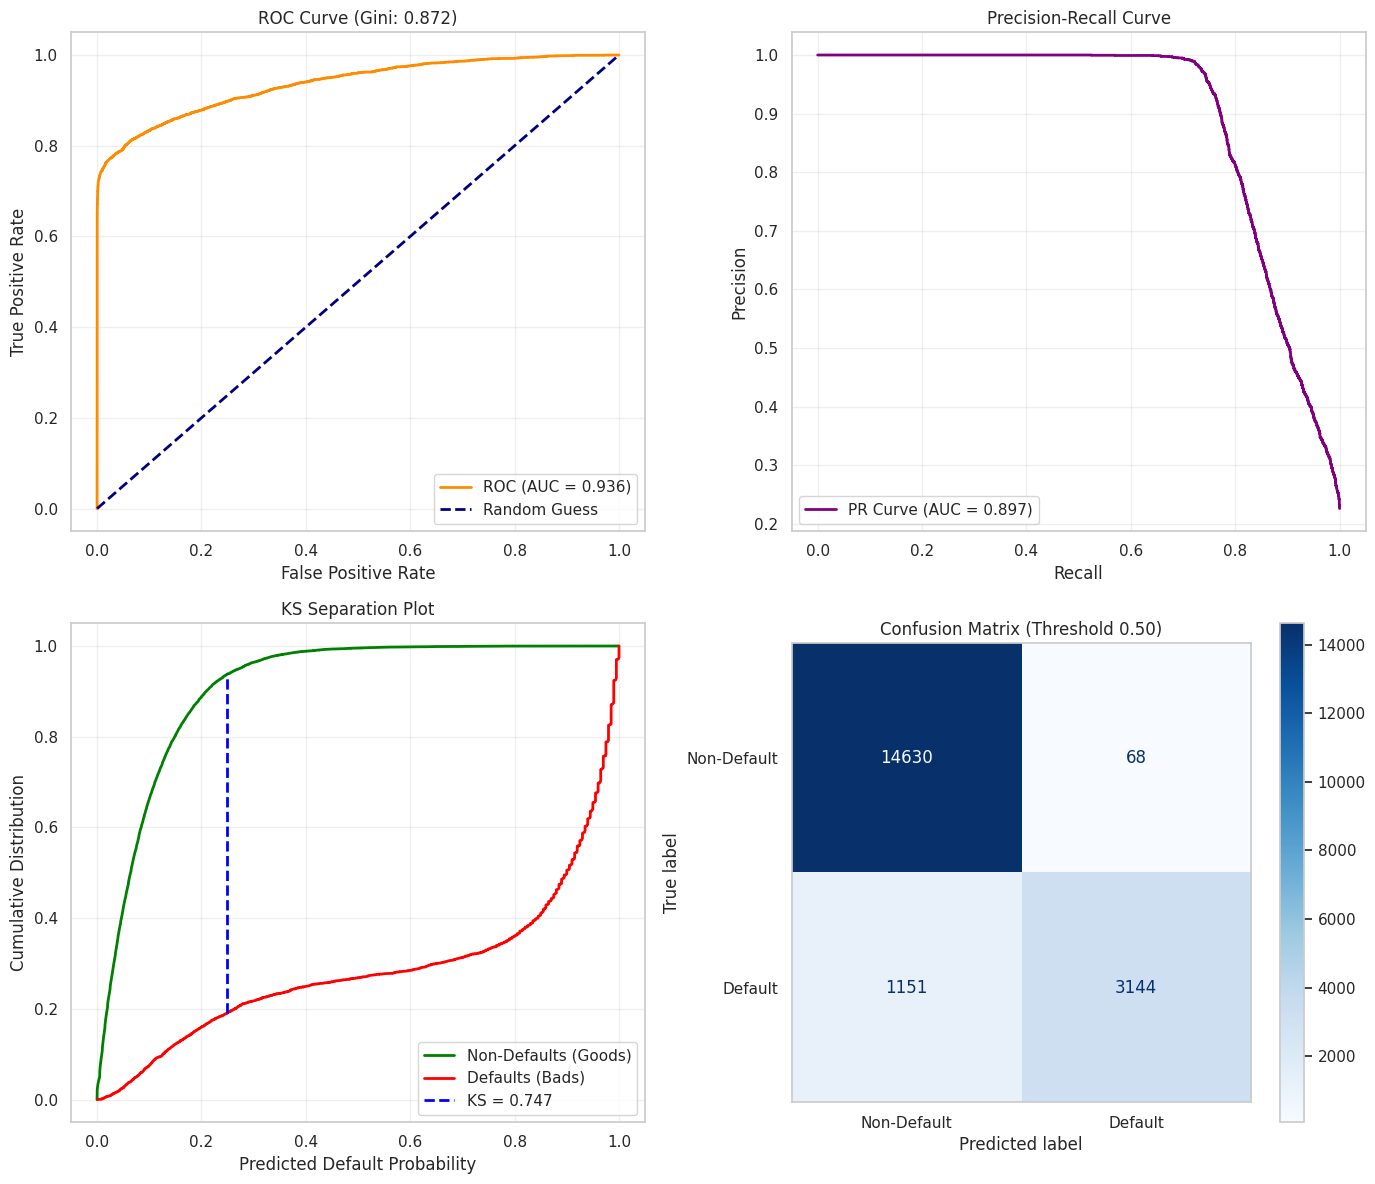

In [28]:
best_rf = grid_search_rf.best_estimator_
oof_probs_rf = cross_val_predict(
    best_rf, X_train, y_train, cv=5, method='predict_proba', n_jobs=-1
)[:, 1]


metrics_rf = evaluate("Random Forest", oof_probs_rf, y_train)
cv_prauc_rf, cv_roc_auc_rf, cv_gini_rf, cv_ks_rf = (
    metrics_rf['prauc'], metrics_rf['roc_auc'], metrics_rf['gini'], metrics_rf['ks']
)

### Model 3: XGBoost

In [29]:
# xgboost pipeline & grid search
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
])

param_grid_xgb = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.8, 1.0]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    scoring='average_precision',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Fitting XGBoost")
grid_search_xgb.fit(X_train, y_train)

best_xgb = grid_search_xgb.best_estimator_
print(f"\nXGB Best PR-AUC: {grid_search_xgb.best_score_:.4f}")
print(f"Best Params: {grid_search_xgb.best_params_}")

Fitting XGBoost
Fitting 5 folds for each of 36 candidates, totalling 180 fits

XGB Best PR-AUC: 0.9144
Best Params: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 7, 'classifier__n_estimators': 200, 'classifier__subsample': 1.0}


=== Cross-Validation Audit (XGBoost) ===
PR-AUC           : 0.9144
ROC-AUC          : 0.9513
Gini Coefficient : 0.9025
KS Statistic     : 0.7701

Classification Report (Threshold = 0.5000):
              precision    recall  f1-score   support

 Non-Default       0.93      0.99      0.96     14698
     Default       0.97      0.75      0.85      4295

    accuracy                           0.94     18993
   macro avg       0.95      0.87      0.90     18993
weighted avg       0.94      0.94      0.94     18993



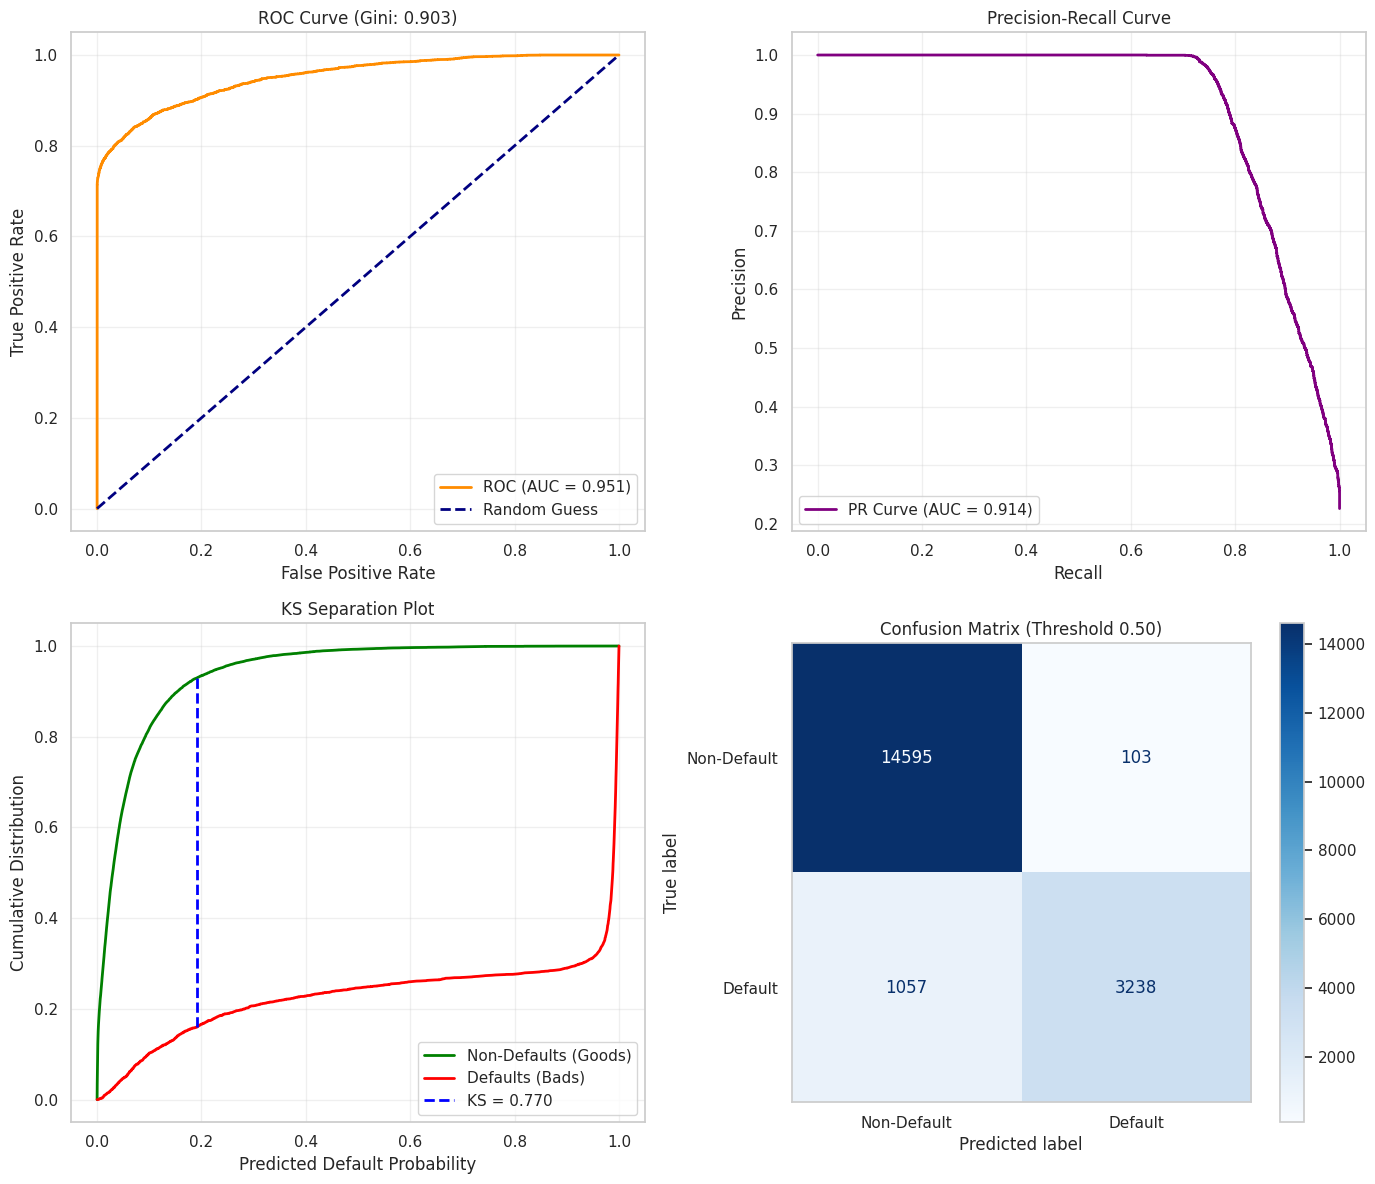

In [30]:
best_xgb = grid_search_xgb.best_estimator_
oof_probs_xgb = cross_val_predict(
    best_xgb, X_train, y_train, cv=5, method='predict_proba', n_jobs=-1
)[:, 1]

metrics_xgb = evaluate("XGBoost", oof_probs_xgb, y_train)
cv_prauc_xgb, cv_roc_auc_xgb, cv_gini_xgb, cv_ks_xgb = (
    metrics_xgb['prauc'], metrics_xgb['roc_auc'], metrics_xgb['gini'], metrics_xgb['ks']
)

## Phase 4: Evaluating Best Model, Feature Importance

In [31]:
# aggregate out of fold CV metrics
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'CV PR-AUC': [cv_prauc_lr, cv_prauc_rf, cv_prauc_xgb],
    'CV ROC-AUC': [cv_roc_auc_lr, cv_roc_auc_rf, cv_roc_auc_xgb],
    'CV Gini': [cv_gini_lr, cv_gini_rf, cv_gini_xgb],
    'CV KS Statistic': [cv_ks_lr, cv_ks_rf, cv_ks_xgb]
}).sort_values('CV PR-AUC', ascending=False).reset_index(drop=True)

print("Cross-Validation Performance Summary:")
display(model_comparison.round(4))

Cross-Validation Performance Summary:


,Model,CV PR-AUC,CV ROC-AUC,CV Gini,CV KS Statistic
0,XGBoost,0.91,0.95,0.90,0.77
1,Random Forest,0.90,0.94,0.87,0.75
2,Logistic Regression,0.72,0.87,0.74,0.58


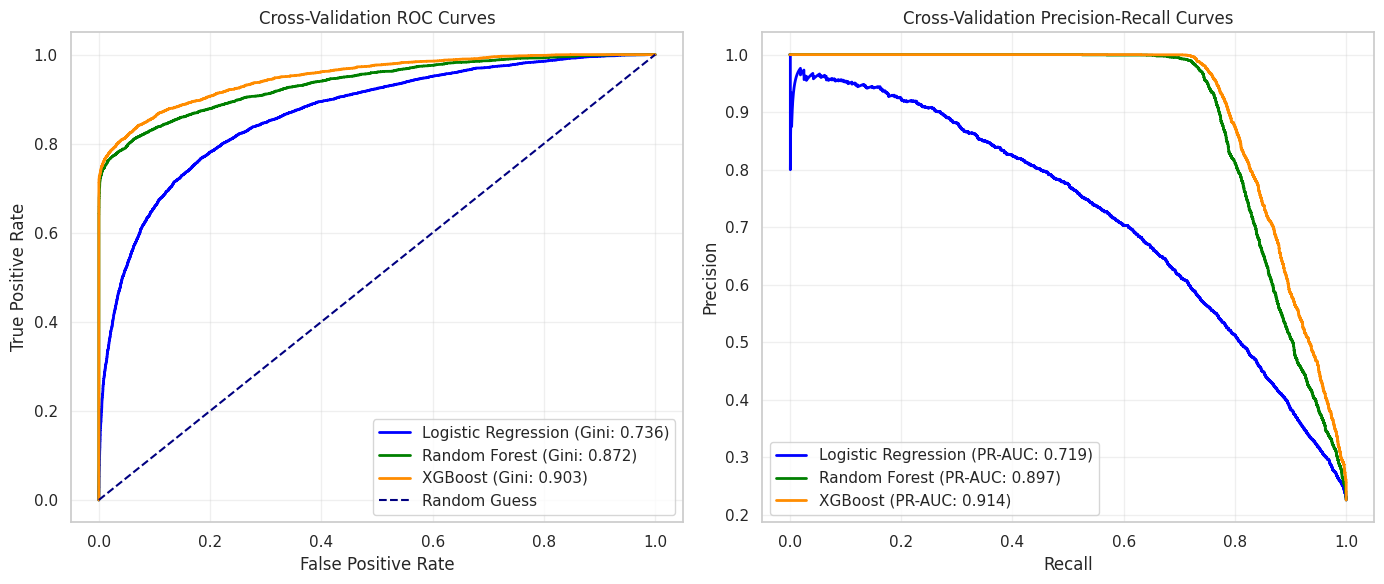

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# roc curves comparison
fpr_lr, tpr_lr, _ = roc_curve(y_train, oof_probs_lr)
axes[0].plot(fpr_lr, tpr_lr, color='blue', label=f'Logistic Regression (Gini: {cv_gini_lr:.3f})', lw=2)

fpr_rf, tpr_rf, _ = roc_curve(y_train, oof_probs_rf)
axes[0].plot(fpr_rf, tpr_rf, color='green', label=f'Random Forest (Gini: {cv_gini_rf:.3f})', lw=2)

fpr_xgb, tpr_xgb, _ = roc_curve(y_train, oof_probs_xgb)
axes[0].plot(fpr_xgb, tpr_xgb, color='darkorange', label=f'XGBoost (Gini: {cv_gini_xgb:.3f})', lw=2)

axes[0].plot([0, 1], [0, 1], color='navy', linestyle='--', lw=1.5, label='Random Guess')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Cross-Validation ROC Curves')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# precision-recall curves comparison
prec_lr, rec_lr, _ = precision_recall_curve(y_train, oof_probs_lr)
axes[1].plot(rec_lr, prec_lr, color='blue', label=f'Logistic Regression (PR-AUC: {cv_prauc_lr:.3f})', lw=2)

prec_rf, rec_rf, _ = precision_recall_curve(y_train, oof_probs_rf)
axes[1].plot(rec_rf, prec_rf, color='green', label=f'Random Forest (PR-AUC: {cv_prauc_rf:.3f})', lw=2)

prec_xgb, rec_xgb, _ = precision_recall_curve(y_train, oof_probs_xgb)
axes[1].plot(rec_xgb, prec_xgb, color='darkorange', label=f'XGBoost (PR-AUC: {cv_prauc_xgb:.3f})', lw=2)

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Cross-Validation Precision-Recall Curves')
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# select champion model and determine optimal decision threshold via Youden's J statistic
champion_model = best_xgb
champion_name = "XGBoost"
oof_probs_champ = oof_probs_xgb

print(f"Champion model: {champion_name}")

# Youden J

fpr, tpr, thresholds = roc_curve(y_train, oof_probs_champ)
j_scores = tpr - fpr
best_threshold_idx = np.argmax(j_scores)
optimal_threshold = thresholds[best_threshold_idx]

print(f"Optimal decision Threshold: {optimal_threshold:.4f}")

Champion model: XGBoost
Optimal decision Threshold: 0.1911


In [34]:
# select champion model
champion_model = best_xgb
champion_name = "XGBoost"
oof_probs_champ = oof_probs_xgb

print(f"Champion model selected: {champion_name}")

# find optimal decision threshold using Youden's J statistic
fpr, tpr, thresholds = roc_curve(y_train, oof_probs_champ)
j_scores = tpr - fpr
best_threshold_idx = np.argmax(j_scores)
optimal_threshold = thresholds[best_threshold_idx]

print(f"Optimal decision threshold: {optimal_threshold:.4f}")

Champion model selected: XGBoost
Optimal decision threshold: 0.1911


=== FINAL TEST SET AUDIT (XGBoost (Test Set)) ===
PR-AUC           : 0.9183
ROC-AUC          : 0.9536
Gini Coefficient : 0.9072
KS Statistic     : 0.7864

Classification Report (Threshold = 0.1911):
              precision    recall  f1-score   support

 Non-Default       0.95      0.93      0.94      3675
     Default       0.79      0.84      0.82      1074

    accuracy                           0.91      4749
   macro avg       0.87      0.89      0.88      4749
weighted avg       0.92      0.91      0.92      4749



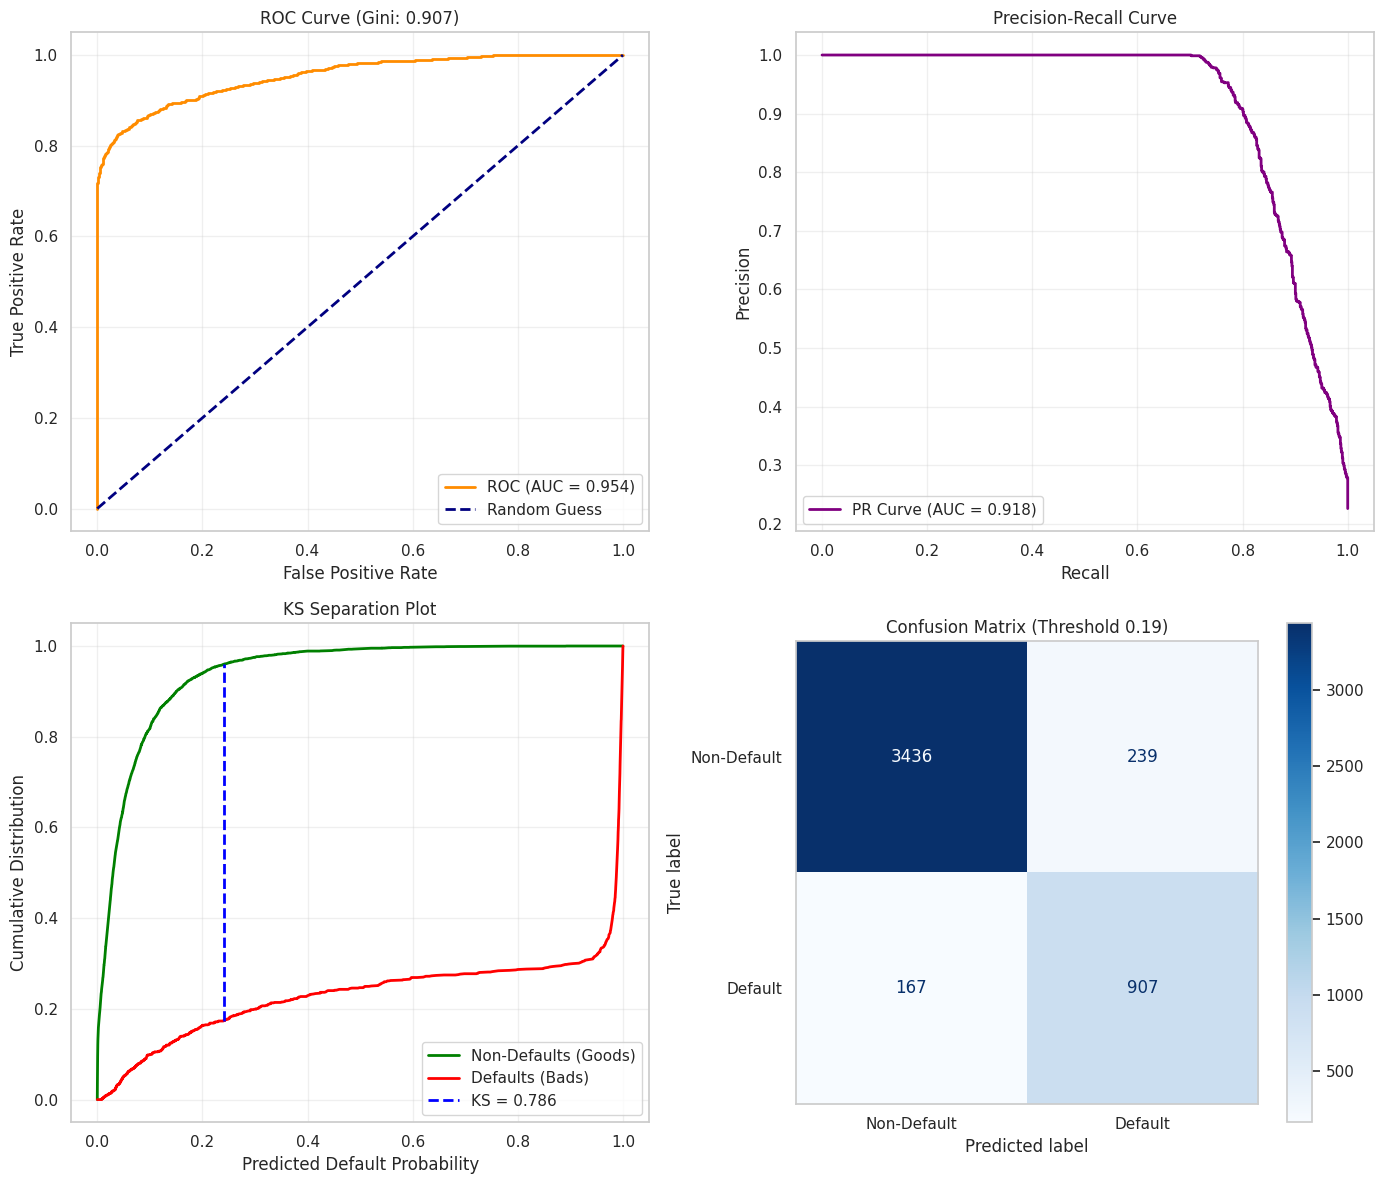

In [35]:
# Validate model on final Test Dataset
test_probs = champion_model.predict_proba(X_test)[:, 1]

# evaluate
test_metrics = evaluate(
    model_name=f"{champion_name} (Test Set)",
    probs=test_probs,
    y=y_test,
    threshold=optimal_threshold,
    is_test_set=True
)

Computing SHAP values...


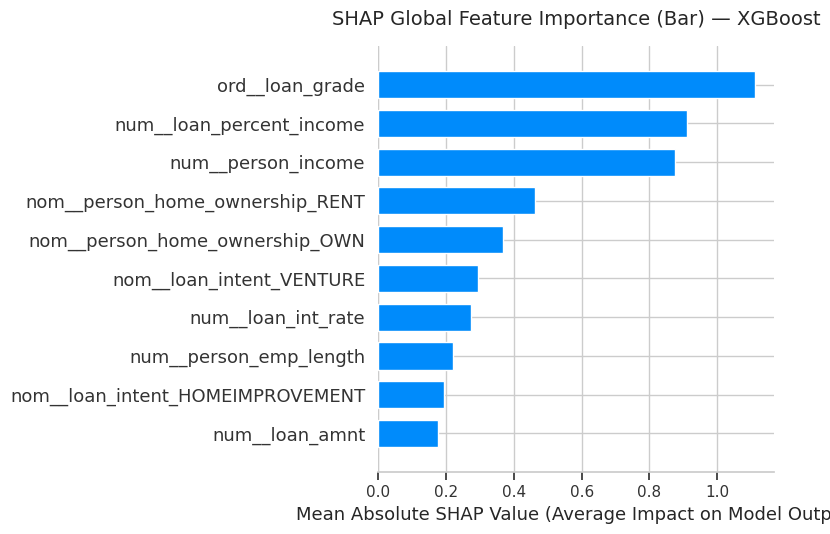

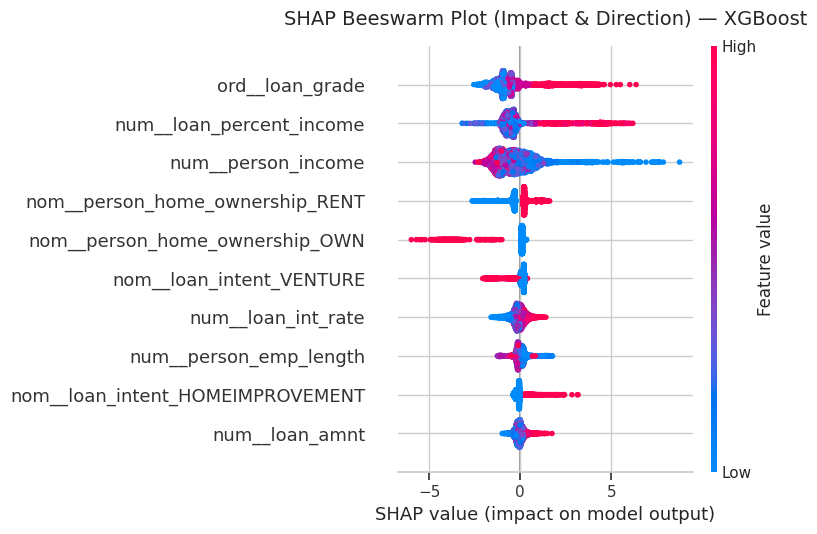

In [36]:
# extract preprocessor and classifier from champion pipeline
preprocessor = champion_model.named_steps['preprocessor']
xgb_classifier = champion_model.named_steps['classifier']

# transform test set features
X_test_transformed = preprocessor.transform(X_test)

try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:
    feature_names = [f"feature_{i}" for i in range(X_test_transformed.shape[1])]

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

# compute shap values using tree explainer
print("Computing SHAP values...")
explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(X_test_df)

if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

# plot 1: global feature importance bar chart
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_to_plot, X_test_df, plot_type="bar", max_display=10, show=False)
plt.title(f"SHAP Global Feature Importance (Bar) — {champion_name}", fontsize=14, pad=15)
plt.xlabel("Mean Absolute SHAP Value (Average Impact on Model Output)")
plt.tight_layout()
plt.show()

# plot 2: beeswarm plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_to_plot, X_test_df, max_display=10, show=False)
plt.title(f"SHAP Beeswarm Plot (Impact & Direction) — {champion_name}", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

=== Individual Applicant Audit (Test Set Index: 10) ===
Actual Outcome      : Default (1)
Model Predicted Prob: 0.9926
Decision Status     : REJECT (Default Risk)



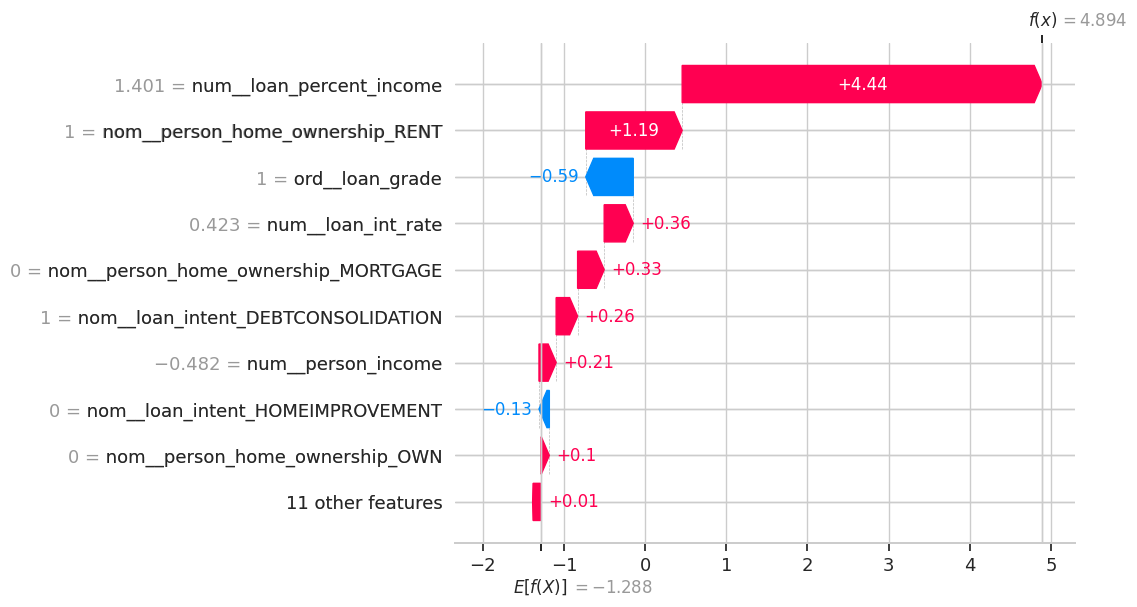

In [37]:
# find a default applicant in the test set to audit
default_indices = np.where(y_test == 1)[0]
sample_index = default_indices[0] if len(default_indices) > 0 else 0

actual_outcome = "Default (1)" if y_test.iloc[sample_index] == 1 else "Non-Default (0)"
predicted_prob = test_probs[sample_index]

print(f"=== Individual Applicant Audit (Test Set Index: {sample_index}) ===")
print(f"Actual Outcome      : {actual_outcome}")
print(f"Model Predicted Prob: {predicted_prob:.4f}")
print(f"Decision Status     : {'REJECT (Default Risk)' if predicted_prob >= optimal_threshold else 'APPROVE (Safe)'}\n")

# generate shap waterfall plot for the selected applicant
explainer_expected_value = explainer.expected_value
if isinstance(explainer_expected_value, list):
    base_val = explainer_expected_value[1]
else:
    base_val = explainer_expected_value

shap_exp = shap.Explanation(
    values=shap_values_to_plot[sample_index],
    base_values=base_val,
    data=X_test_df.iloc[sample_index],
    feature_names=X_test_df.columns.tolist()
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_exp, max_display=10, show=True)